In [4]:
import sys
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(os.path.join(os.getcwd(), '../'))
from utils_mouse import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils

In [5]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)

<module 'utils.plot_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/plot_utils.py'>

In [6]:
# read_ids = list(range(0, 8+1))
read_ids = [2]
plot_id = 2

In [7]:
# read
path = os.path.join(read_utils.get_data_path(), '6163622/sessions')
(file_ids, filenames,
 traces,
 continuous_behaviors,
 motion_pcs,
 motion_masks) = read_utils.get_datas(path, read_ids,
									  with_whisking=True)

# # clear nan values
for i in range(len(file_ids)):
	# mask = motion_pcs[i][0].notna().all(axis=1)
	mask = continuous_behaviors[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	motion_pcs[i][0] = motion_pcs[i][0][mask]
	motion_pcs[i][1] = motion_pcs[i][1][mask]
	continuous_behaviors[i] = continuous_behaviors[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [8]:
plot_idx = file_ids.index(plot_id)

# states = [ds[selection_bhl] for ds in states]

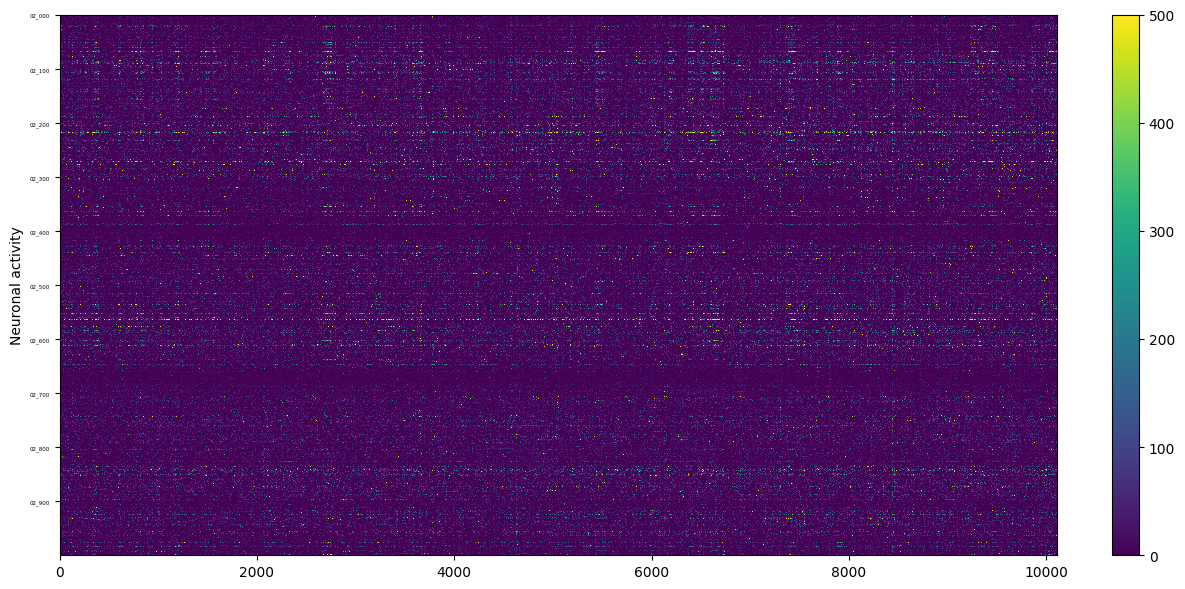

In [9]:
plot_utils.plot_heatmap_stack(traces[plot_idx].iloc[:, :1000], None,
							  label_traces='Neuronal activity', label_behavior=None,
							  height_ratios=(0, 1),
							  zlimits_activity=(0, 500), cmap='viridis')

(array([8.939e+03, 8.940e+02, 2.200e+02, 3.300e+01, 1.000e+01, 4.000e+00,
        2.000e+00, 1.000e+00, 1.000e+00, 1.000e+00]),
 array([  0.        ,  10.44209862,  20.88419724,  31.32629585,
         41.76839447,  52.210495  ,  62.65259171,  73.09468842,
         83.53678894,  93.97888947, 104.42098999]),
 <BarContainer object of 10 artists>)

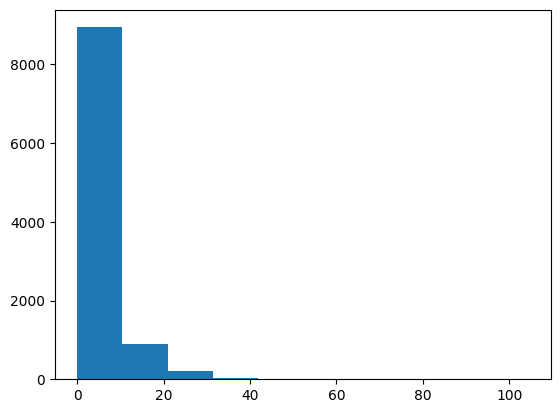

In [13]:
plt.hist(traces[plot_idx].values[:, 0])

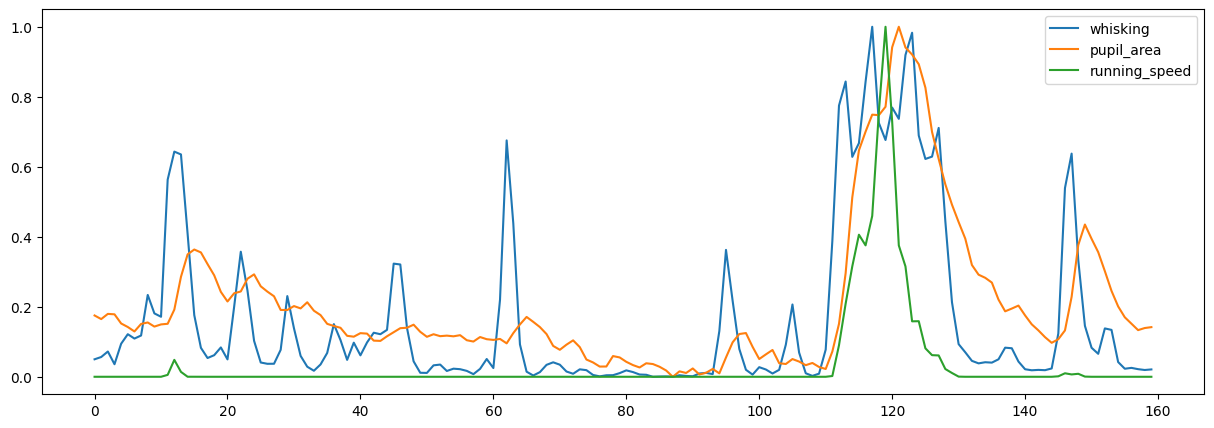

In [14]:
fig, ax = plt.subplots(len(file_ids), 1, squeeze=False, figsize=(15, 5))
for file_id in file_ids:
	whisking = continuous_behaviors[file_ids.index(file_id)][['whisking']].values[:160]
	running_speed = continuous_behaviors[file_ids.index(file_id)][['running_speed']].values[:160]
	pupil_area = continuous_behaviors[file_ids.index(file_id)][['pupil_area']].values[:160]

	whisking = (whisking - whisking.min()) / (whisking.max() - whisking.min())
	running_speed = (running_speed - running_speed.min()) / (running_speed.max() - running_speed.min())
	pupil_area = (pupil_area - pupil_area.min()) / (pupil_area.max() - pupil_area.min())

	ax[file_ids.index(file_id), 0].plot(whisking, label='whisking')
	ax[file_ids.index(file_id), 0].plot(pupil_area, label='pupil_area')
	ax[file_ids.index(file_id), 0].plot(running_speed, label='running_speed')
	ax[file_ids.index(file_id), 0].legend()

Text(0.5, 1.0, 'pupil com x (blue) and pupil com y (orange)')

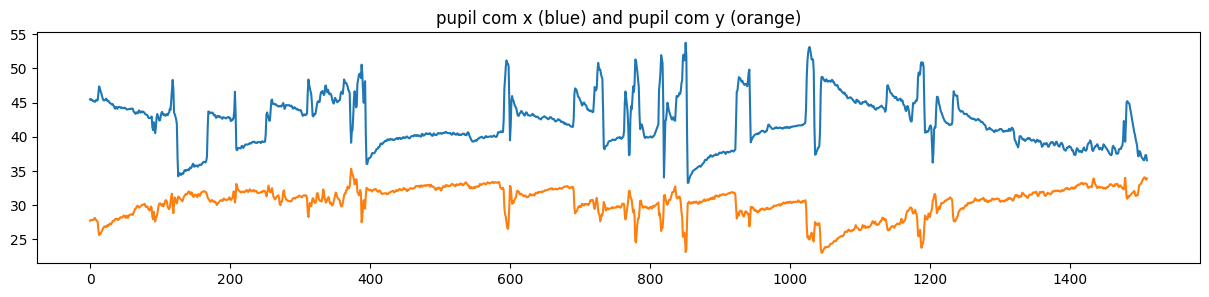

In [16]:
plt.figure(figsize=(15, 3))
plt.plot()
plt.plot(continuous_behaviors[plot_idx]['pupil_com_x'].iloc[:1500])
plt.plot(continuous_behaviors[plot_idx]['pupil_com_y'].iloc[:1500])
plt.title('pupil com x (blue) and pupil com y (orange)')

(array([8.924e+03, 5.120e+02, 2.680e+02, 1.970e+02, 1.200e+02, 5.500e+01,
        1.800e+01, 5.000e+00, 5.000e+00, 1.000e+00]),
 array([ 0.        ,  2.06337488,  4.12674975,  6.19012463,  8.2534995 ,
        10.31687438, 12.38024926, 14.44362413, 16.50699901, 18.57037388,
        20.63374876]),
 <BarContainer object of 10 artists>)

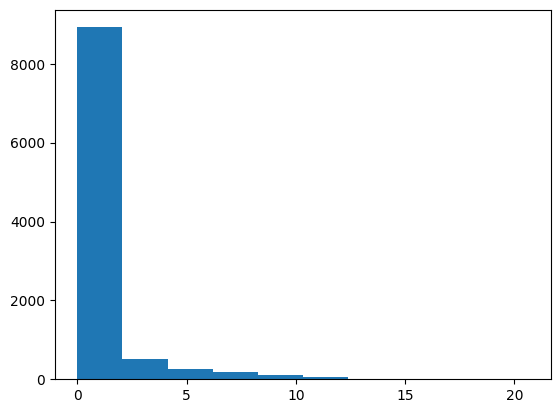

In [15]:
plt.hist(continuous_behaviors[plot_idx][['running_speed']].values[:, 0])

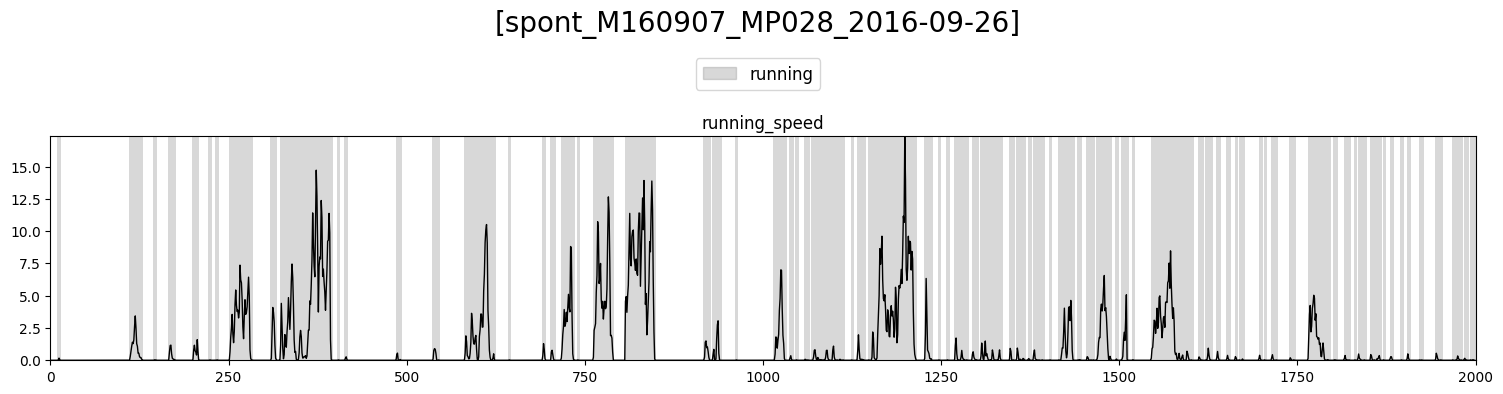

In [25]:
classes = continuous_behaviors[0][['running_speed']].values > np.quantile(continuous_behaviors[0][['running_speed']].values, 0.05)

plot_utils.plot_traces(continuous_behaviors[0][['running_speed']].iloc[:2000],
					   pd.DataFrame(data=classes[:2000] * 30, columns=continuous_behaviors[0][['running_speed']].columns),
					   label='running',
					   title=f'[{filenames[plot_idx]}]', ylimits=None, plots_per_row=1)

In [18]:
# correlation = traces[plot_idx].iloc[:1500, :1000].corr()
# heatmap = sns.clustermap(correlation, yticklabels=True, xticklabels=True)
# heatmap.ax_heatmap.set_yticklabels(heatmap.ax_heatmap.get_yticklabels(), fontsize=5)
# heatmap.ax_heatmap.set_xticklabels(heatmap.ax_heatmap.get_xticklabels(), fontsize=5)
# heatmap.ax_heatmap.tick_params(axis='x', bottom=True, top=False)
#
# plt.title(f'{filenames[plot_idx]}', y=1.05, fontsize=8)
# plt.show()

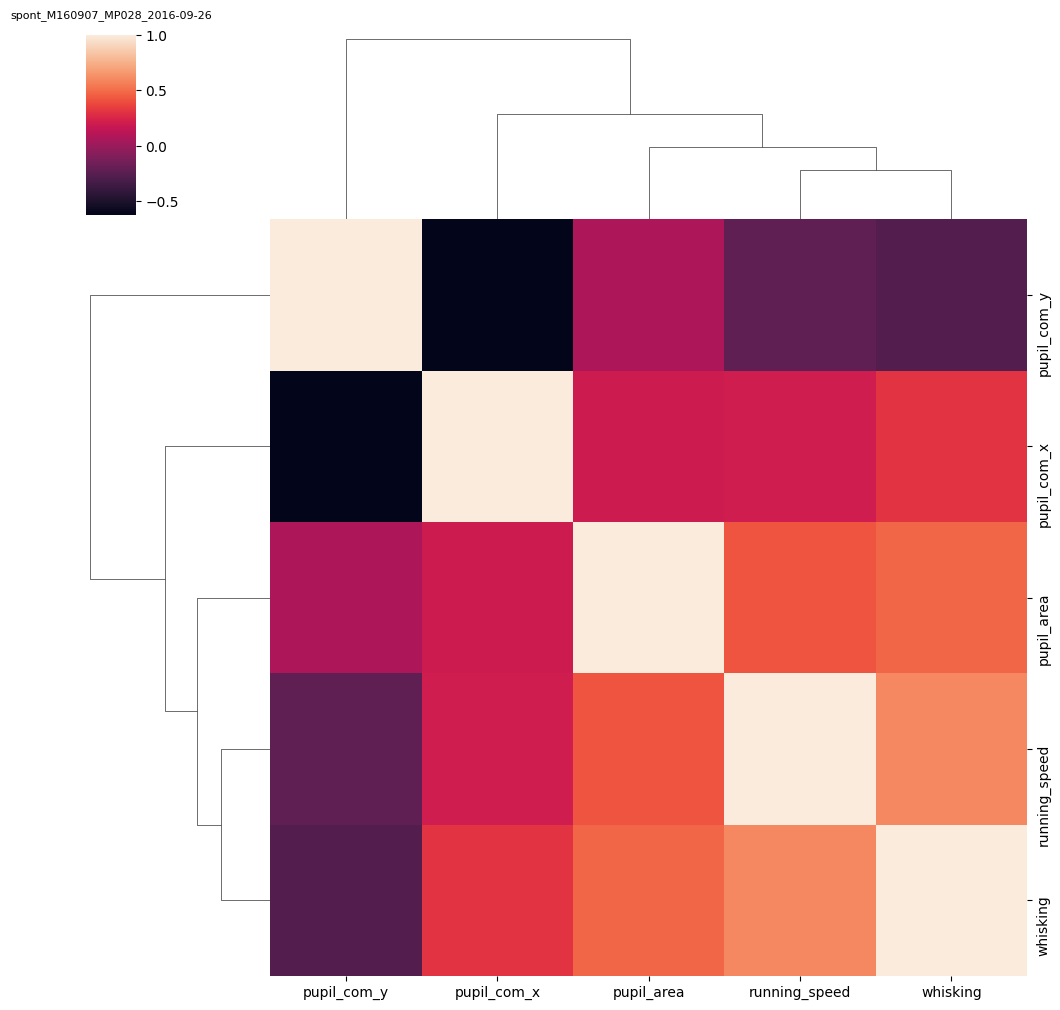

In [19]:
correlation = continuous_behaviors[plot_idx].corr()
heatmap = sns.clustermap(correlation, yticklabels=True, xticklabels=True)
heatmap.ax_heatmap.set_yticklabels(heatmap.ax_heatmap.get_yticklabels(), fontsize=10)
heatmap.ax_heatmap.set_xticklabels(heatmap.ax_heatmap.get_xticklabels(), fontsize=10)
heatmap.ax_heatmap.tick_params(axis='x', bottom=True, top=False)

plt.title(f'{filenames[plot_idx]}', y=1.05, fontsize=8)
plt.show()

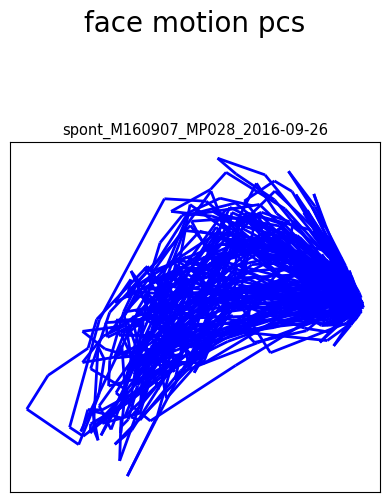

In [20]:
plot_utils.plot_manifolds(filenames,
						  [motion_pc[0][['PC1', 'PC2']].iloc[:1500] for motion_pc in motion_pcs],
						  None,
						  title='face motion pcs', top_space=1)

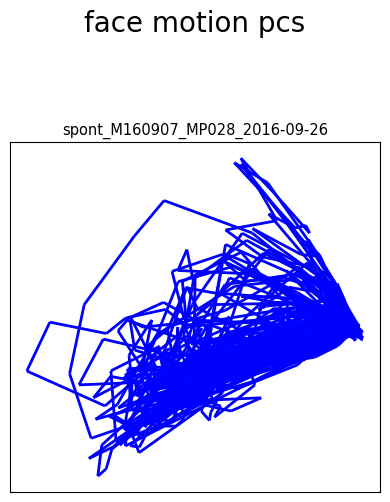

In [21]:
plot_utils.plot_manifolds(filenames,
						  [motion_pc[1][['PC1', 'PC2']].iloc[:1500] for motion_pc in motion_pcs],
						  None,
						  title='face motion pcs', top_space=1)

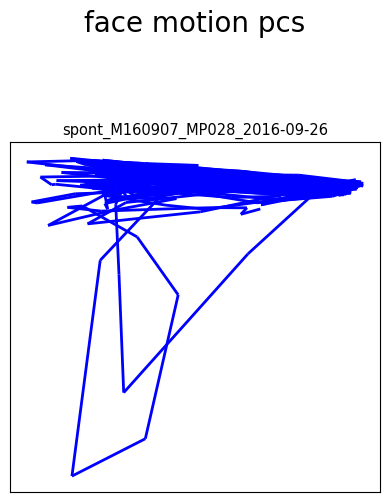

In [22]:
plot_utils.plot_manifolds(filenames,
						  [motion_pc[2][['PC1', 'PC2']].iloc[:1500] for motion_pc in motion_pcs],
						  None,
						  title='face motion pcs', top_space=1)

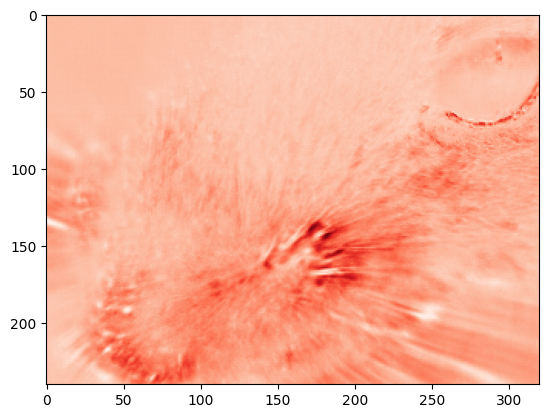

In [23]:
face_weights = motion_pcs[plot_idx][0]
face_loadings = motion_masks[plot_idx][0][0]

w1 = face_weights.values[1, :].reshape(1, -1)
l1 = face_loadings.values
f1 = w1 @ l1

ar = motion_masks[plot_idx][0][1]
f1 = f1.reshape(-1, ar[0], ar[1])

plt.imshow(f1.T, cmap='Reds_r')

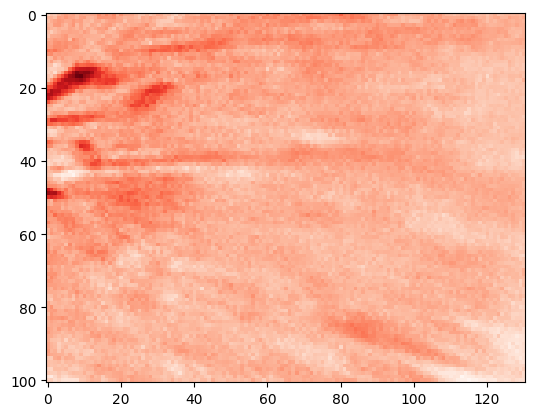

In [24]:
whisk_weights = motion_pcs[plot_idx][1]
whisk_loadings = motion_masks[plot_idx][1][0]

w1 = whisk_weights.values[1, :].reshape(1, -1)
l1 = whisk_loadings.values
f1 = w1 @ l1

ar = motion_masks[plot_idx][1][1]
f1 = f1.reshape(-1, ar[0], ar[1])

plt.imshow(f1.T, cmap='Reds_r')